Энэ dataset нь 2011–2012 оны UCI Bike Sharing өгөгдөл бөгөөд Вашингтон, D.C. орчмын Capital Bikeshare системийн мэдээлэл юм. Тиймээс эцсийн assignment title болон poster дээрээ Dublin Bike Sharing гэж бичихгүй, өгөгдлийн бодит байршил, эх сурвалжийг зөв тусгаарай.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os

os.environ["OMP_NUM_THREADS"] = "3"

In [5]:
# Load the Bike Sharing Dataset
df = pd.read_csv("day.csv")

# Display first 5 rows
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In this section, I explored the Bike Sharing Dataset to understand the data before applying machine learning algorithms.

In [6]:
# Check dataset shape
print("Dataset shape:", df.shape)

# Check data types
df.info()

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Statistical summary
df.describe()

Dataset shape: (731, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
instant       0
dteday        0
season        0
yr            0
mnth

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


The dataset contains **731 observations and 16 columns**. Moreover, I checked the dataset for missing values and found that there were **no missing values**.

## Exploratory Data Analysis (EDA)

In [7]:
# Convert date column to datetime format
df["dteday"] = pd.to_datetime(df["dteday"])

# Check the date range
print("Start Date:", df["dteday"].min())
print("End Date:", df["dteday"].max())

Start Date: 2011-01-01 00:00:00
End Date: 2012-12-31 00:00:00


The dataset is covering daily bike rental information **from 2011 to 2012**.

### 5.3 Daily Bike Rental Demand graphic

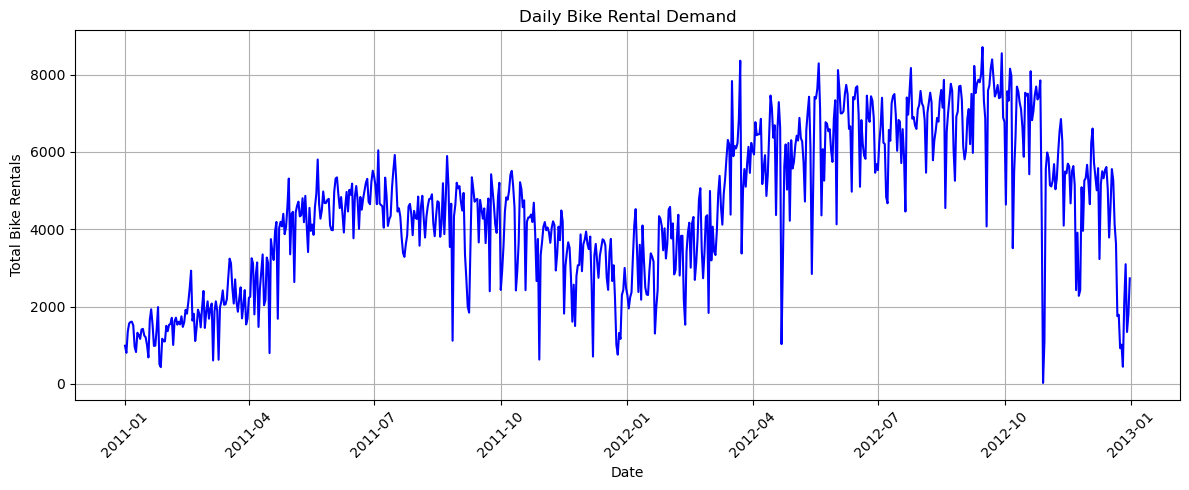

In [8]:
# Plot daily bike rental demand
plt.figure(figsize=(12, 5))

plt.plot(
    df["dteday"],
    df["cnt"],
    color="blue"
)

plt.title("Daily Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

### Interpretation: Daily Bike Rental Demand

The line graph shows the daily bike rental demand between 2011 and 2012.

Overall, bike rental demand increased during this period. The number of rentals was generally higher in 2012 compared to 2011.

The graph also shows seasonal patterns, with higher demand during warmer periods and lower demand during colder periods.

There are some sudden decreases in bike rentals, which may be related to weather conditions or other external factors.

This analysis suggests that time series forecasting could be useful for predicting future bike rental demand.

### 5.4 Average Bike Rentals by Season

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64


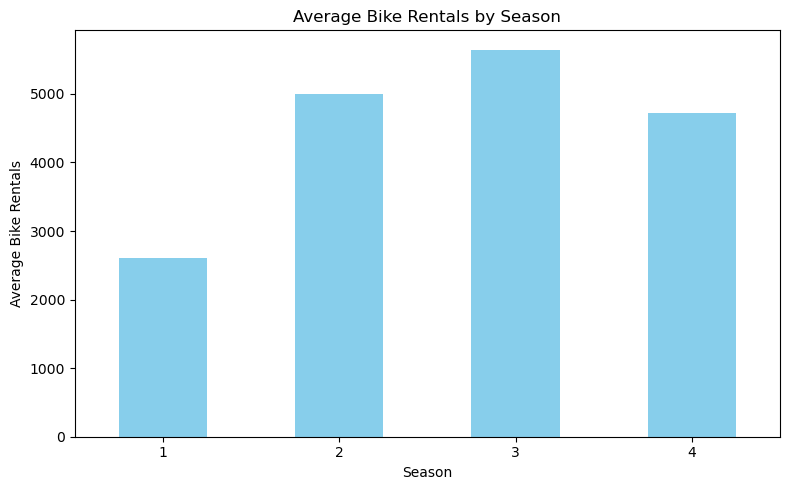

In [9]:
# Calculate average rentals by season
season_avg = df.groupby("season")["cnt"].mean()

print(season_avg)

# Plot seasonal demand
plt.figure(figsize=(8, 5))

season_avg.plot(
    kind="bar",
    color="skyblue"
)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Bike Rentals")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Interpretation: Average Bike Rentals by Season
The season code meaning is in UCI dataset 1 = Spring, 2 = Summer, 3 = Fall, 4 = Winter

The bar chart compares the average number of bike rentals across four seasons.

Autumn has the highest average demand, with approximately 5,644 rentals per day. Summer follows with around 4,992 rentals, while winter has approximately 4,728 rentals.

Spring has the lowest average demand, with approximately 2,604 rentals per day.

These results suggest that seasonality is an important factor influencing bike rental demand.

Understanding these seasonal differences could help bike-sharing companies improve resource allocation and operational planning.

### 5.5 Correlation Heatmap

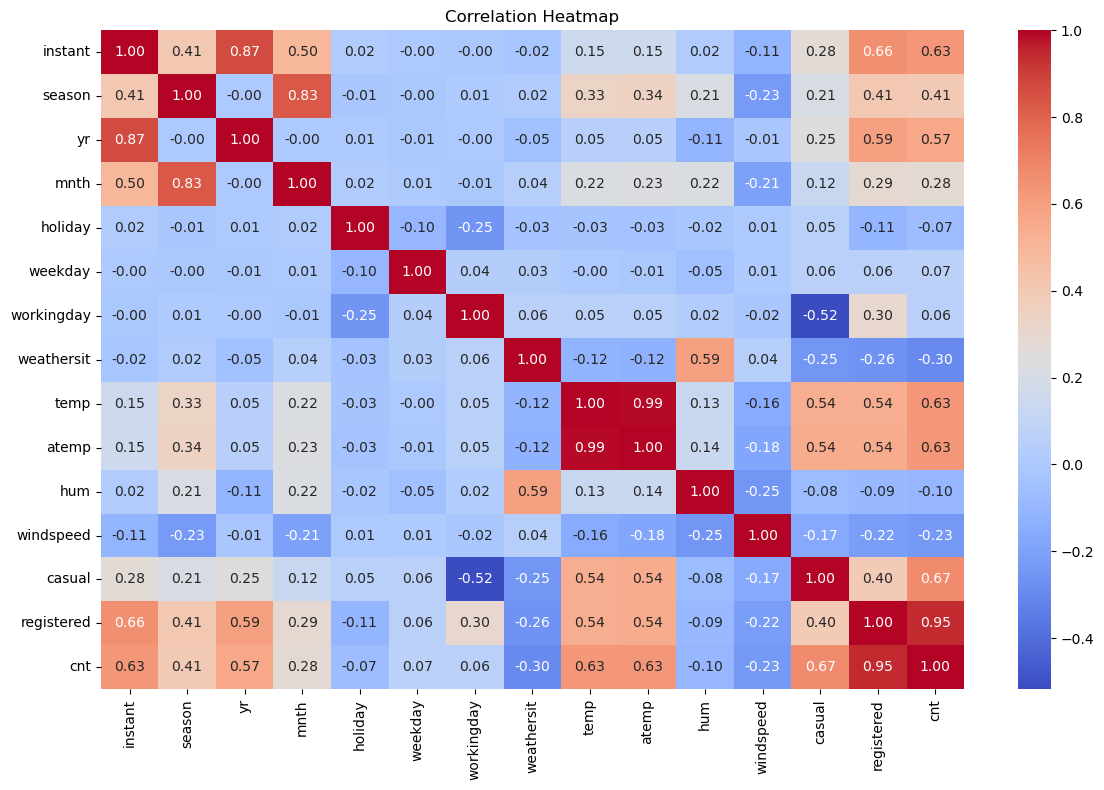

In [10]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Exploratory Data Analysis (EDA)

In this section, I used descriptive statistics and visualisations to investigate bike rental demand. These included a daily rental demand line graph, a seasonal demand bar chart, and a correlation heatmap.

The purpose of this analysis is to identify patterns and relationships in the data before applying clustering and time series forecasting models.

### Interpretation: Correlation Heatmap

The correlation heatmap shows the relationships between numerical variables in the Bike Sharing Dataset.

Temperature has a positive correlation of approximately 0.63 with total bike rentals. This suggests that bike rental demand tends to increase as temperature rises.

Weather conditions have a negative correlation of approximately -0.30 with total rentals, while windspeed has a correlation of approximately -0.23.

Registered and casual rentals are strongly correlated with total rentals because they are components of the total rental count.

Overall, the heatmap suggests that temperature and weather conditions are useful variables to investigate when analysing bike rental demand. However, correlation does not necessarily imply causation.

## 6. Clustering Analysis

### 6.1 Feature Selection and Data Scaling

In this section, I apply unsupervised machine learning algorithms to identify different patterns in bike rental demand.

I selected temperature, humidity, windspeed and total bike rentals as the main features for clustering.

These features represent weather conditions and bike rental activity. StandardScaler is used to standardise the selected variables so that differences in their numerical scales do not dominate the clustering results.

In [11]:
from sklearn.preprocessing import StandardScaler

# Select features for clustering
features = ["temp", "hum", "windspeed", "cnt"]

X = df[features].copy()

# Standardise the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original dataset shape:", X.shape)
print("Scaled dataset shape:", X_scaled.shape)

X.head()

Original dataset shape: (731, 4)
Scaled dataset shape: (731, 4)


,temp,hum,windspeed,cnt
0,0.344167,0.805833,0.160446,985
1,0.363478,0.696087,0.248539,801
2,0.196364,0.437273,0.248309,1349
3,0.200000,0.590435,0.160296,1562
4,0.226957,0.436957,0.186900,1600


### 6.2 Find the Best Number of Clusters

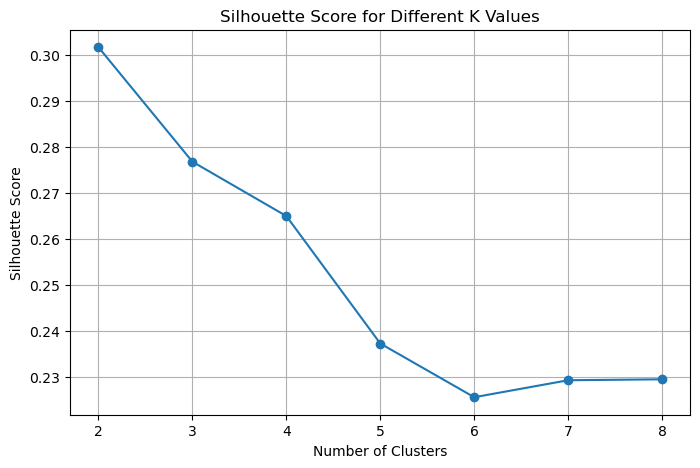

Best number of clusters: 2
Best Silhouette Score: 0.3016611538502967


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Best number of clusters:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

### Interpretation: Optimal Number of Clusters

I used the Silhouette Score to find the most suitable number of clusters for the K-Means algorithm.

I tested cluster numbers from 2 to 8. The highest Silhouette Score was approximately 0.302 when the number of clusters was 2.

As the number of clusters increased, the Silhouette Score generally decreased.

Therefore, I selected two clusters for the K-Means model.

However, the score of 0.302 suggests that the clusters are only moderately separated, and some overlap may exist between the groups.

### 6.3 Apply K-Means Clustering

In [13]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster distribution:")
print(df["KMeans_Cluster"].value_counts().sort_index())

df[["dteday", "cnt", "KMeans_Cluster"]].head()

Cluster distribution:
KMeans_Cluster
0    313
1    418
Name: count, dtype: int64


,dteday,cnt,KMeans_Cluster
0,2011-01-01,985,0
1,2011-01-02,801,0
2,2011-01-03,1349,0
3,2011-01-04,1562,0
4,2011-01-05,1600,0


In [14]:
# Calculate average values for each cluster
cluster_profile = df.groupby("KMeans_Cluster")[
    ["temp", "hum", "windspeed", "cnt"]
].mean()

print("K-Means Cluster Profiles:")
display(cluster_profile.round(2))

K-Means Cluster Profiles:


,temp,hum,windspeed,cnt
KMeans_Cluster,,,,
0,0.33,0.59,0.22,2966.57
1,0.62,0.65,0.17,5655.84


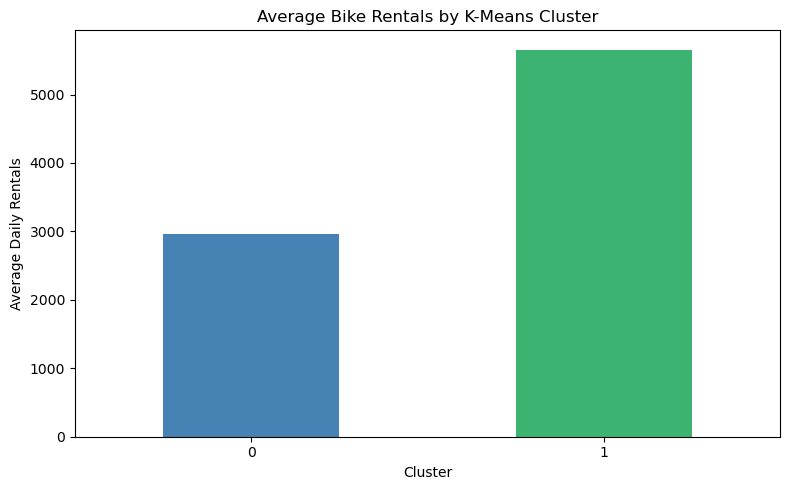

In [15]:
# Visualise average rentals by cluster
cluster_profile["cnt"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "mediumseagreen"]
)

plt.title("Average Bike Rentals by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation: K-Means Clustering

The K-Means algorithm divided the dataset into two clusters.

Cluster 0 contains 313 observations, while Cluster 1 contains 418 observations.

The scatter plot shows that the two groups have different patterns of temperature and bike rental demand. Cluster 0 generally includes days with lower rental demand, while Cluster 1 contains many days with higher rental demand.

However, some observations overlap between the two clusters.

The results suggest that clustering can help identify different bike rental demand patterns. These patterns could support better planning and resource allocation for bike-sharing services.

### 6.4 Visualise K-Means Clusters

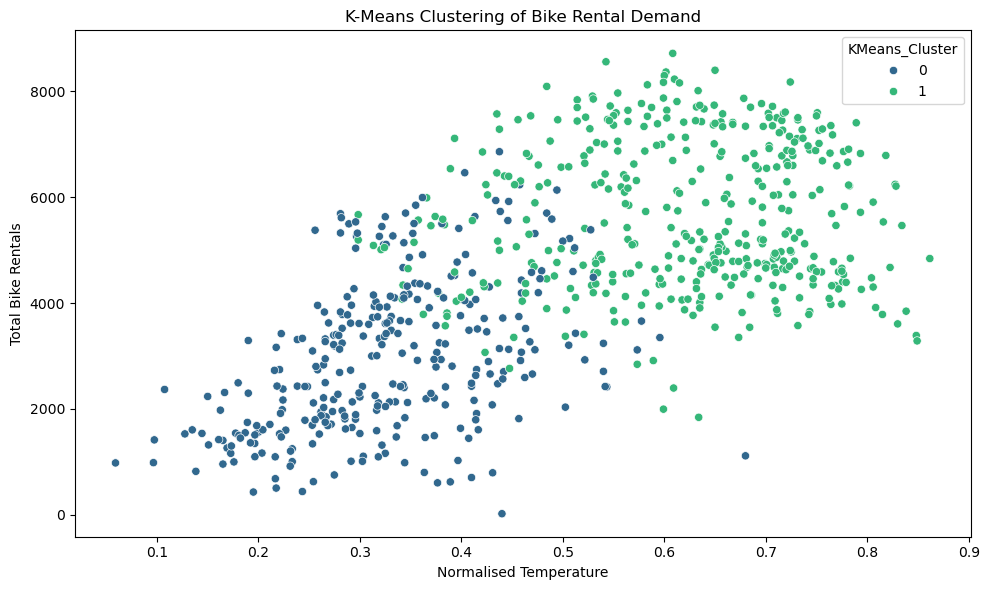

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    hue="KMeans_Cluster",
    palette="viridis"
)

plt.title("K-Means Clustering of Bike Rental Demand")
plt.xlabel("Normalised Temperature")
plt.ylabel("Total Bike Rentals")
plt.tight_layout()
plt.show()

### 6.5 Agglomerative Clustering

In [17]:
from sklearn.cluster import AgglomerativeClustering

agg_model = AgglomerativeClustering(
    n_clusters=best_k
)

df["Agg_Cluster"] = agg_model.fit_predict(X_scaled)

print("Agglomerative Cluster Distribution:")
print(df["Agg_Cluster"].value_counts().sort_index())

Agglomerative Cluster Distribution:
Agg_Cluster
0    437
1    294
Name: count, dtype: int64


### Interpretation: Agglomerative Clustering

Agglomerative Clustering was applied to the same standardised dataset using two clusters.

The algorithm divided the 731 observations into two groups, containing 437 and 294 observations respectively.

Unlike K-Means, which uses cluster centres, Agglomerative Clustering combines observations based on their similarities.

The Silhouette Score was approximately 0.248, while the Davies–Bouldin Index was approximately 1.438.

These results suggest that Agglomerative Clustering produced less clearly separated groups than K-Means for this dataset and configuration.

### 6.6 Compare Both Clustering Algorithms

In [18]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

results = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative"],
    "Silhouette Score": [
        silhouette_score(X_scaled, df["KMeans_Cluster"]),
        silhouette_score(X_scaled, df["Agg_Cluster"])
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_scaled, df["KMeans_Cluster"]),
        davies_bouldin_score(X_scaled, df["Agg_Cluster"])
    ]
})

results

,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.301661,1.359205
1,Agglomerative,0.247848,1.438407


### 6.7 Cluster Profile Analysis

In [19]:
# Calculate average values for each cluster
cluster_profile = df.groupby("KMeans_Cluster")[
    ["temp", "hum", "windspeed", "cnt"]
].mean()

print("K-Means Cluster Profiles:")
display(cluster_profile.round(2))

K-Means Cluster Profiles:


,temp,hum,windspeed,cnt
KMeans_Cluster,,,,
0,0.33,0.59,0.22,2966.57
1,0.62,0.65,0.17,5655.84


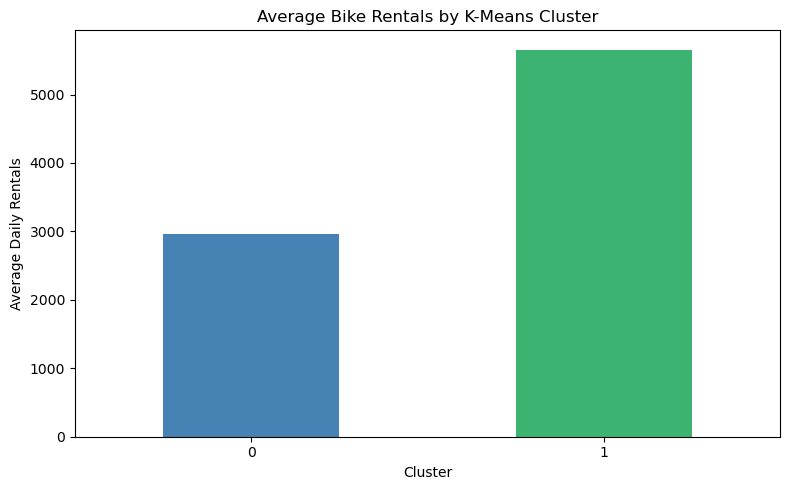

In [20]:
# Visualise average rentals by cluster
cluster_profile["cnt"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "mediumseagreen"]
)

plt.title("Average Bike Rentals by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Comparison of Clustering Algorithms and Conclusion

In this analysis, I compared K-Means and Agglomerative Clustering using the Silhouette Score and Davies–Bouldin Index.

K-Means achieved a Silhouette Score of 0.302 and a Davies–Bouldin Index of 1.359.

Agglomerative Clustering achieved a lower Silhouette Score of 0.248 and a higher Davies–Bouldin Index of 1.438.

A higher Silhouette Score indicates better cluster separation, while a lower Davies–Bouldin Index indicates more compact and separated clusters.

Based on these evaluation metrics, K-Means performed better than Agglomerative Clustering in this experiment.

However, the relatively low Silhouette Scores indicate that the clustering structure is not strongly separated. Further feature selection or alternative clustering settings may improve the results.

From a business perspective, these clusters could help identify different patterns of bike rental demand and support decisions about resource planning.

## 7. Time Series Forecasting

### 7.1 Data Preparation

In this section, I use time series forecasting methods to analyse and predict daily bike rental demand.

The dataset contains daily bike rental records from January 2011 to December 2012.

I use the date column as the time index and the total rental count as the target variable.

The main objective is to investigate trends and seasonal patterns and evaluate how accurately ARIMA and SARIMA models can forecast bike rental demand.

In [55]:
# Prepare time series data
ts = df[["dteday", "cnt"]].copy()

# Convert date column
ts["dteday"] = pd.to_datetime(ts["dteday"])

# Sort by date
ts = ts.sort_values("dteday")

# Set date as index
ts = ts.set_index("dteday")

# Set daily frequency
ts = ts.asfreq("D")

# Check the dataset
print("Time Series Shape:", ts.shape)

print("Missing Values:")
print(ts.isnull().sum())

display(ts.head())

Time Series Shape: (731, 1)
Missing Values:
cnt    0
dtype: int64


,cnt
dteday,
2011-01-01,985
2011-01-02,801
2011-01-03,1349
2011-01-04,1562
2011-01-05,1600


## 7.2 Plot the Time Series

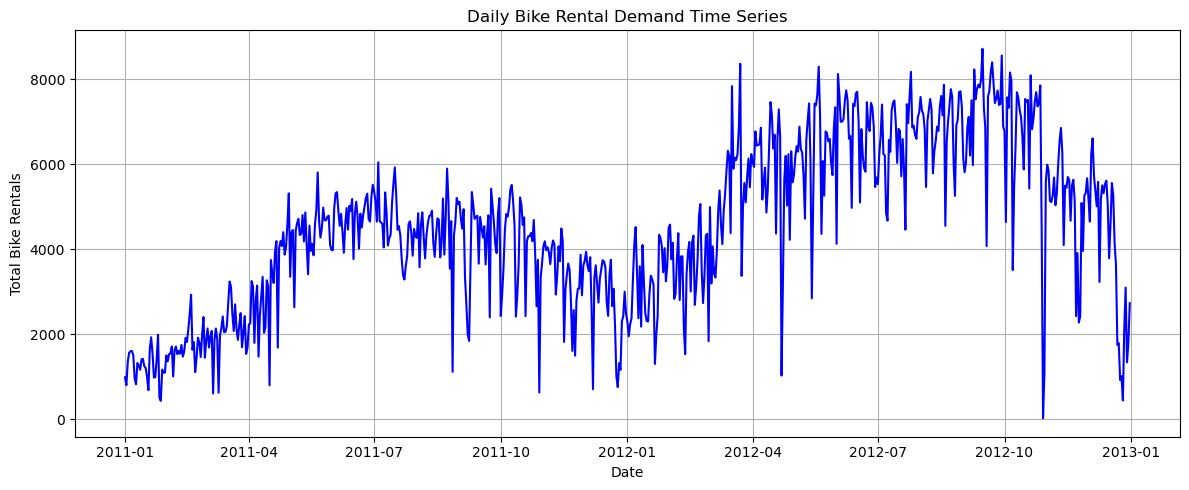

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(
    ts.index,
    ts["cnt"],
    color="blue"
)

plt.title("Daily Bike Rental Demand Time Series")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.grid(True)
plt.tight_layout()
plt.show()

## 7.3 Train/Test Split

In [57]:
# Split data into training and testing sets
train_size = int(len(ts) * 0.8)

train = ts["cnt"].iloc[:train_size]
test = ts["cnt"].iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 584
Testing observations: 147
Training period: 2011-01-01 00:00:00 to 2012-08-06 00:00:00
Testing period: 2012-08-07 00:00:00 to 2012-12-31 00:00:00


## 7.4 Visualise Train/Test Split

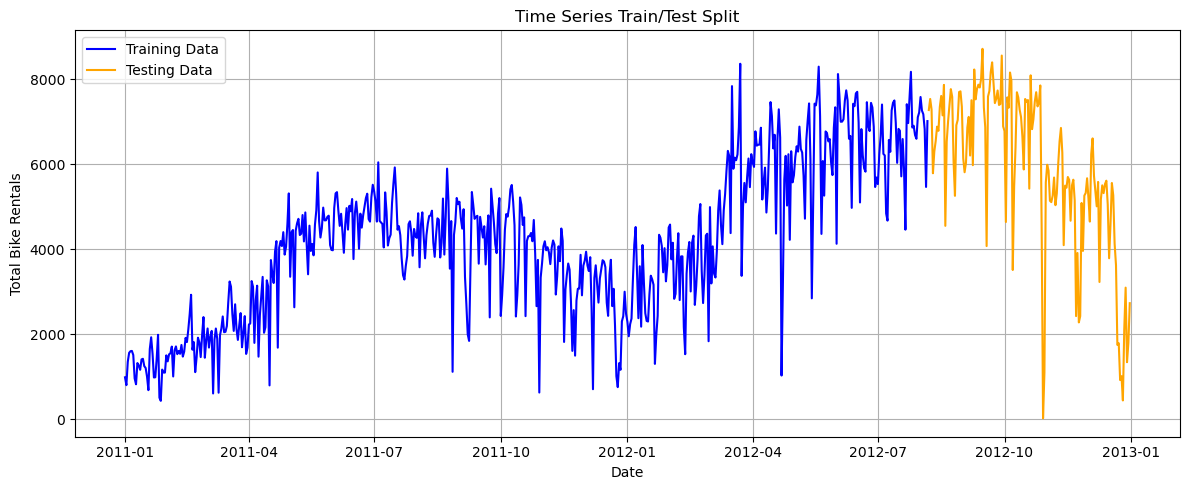

In [58]:
plt.figure(figsize=(12, 5))

plt.plot(
    train.index,
    train,
    label="Training Data",
    color="blue"
)

plt.plot(
    test.index,
    test,
    label="Testing Data",
    color="orange"
)

plt.title("Time Series Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()